Step 1: Split the received signal as ref signal \& loc signal. Get the basic information including sample rate, starting time, etc.

In [1]:
from preproc import preproc
import os
import scipy.io as sio
# iq0_path = '/home/ishani/LeoPNT/USRP_data/12_27/time_20_47_freq_11_325G_bw_2.0M_1703724657.2378652_inrx0.dat'
# sample_rate = 2e6
# date = "12_27"
# start_time = 1703724657.2378652
iq0_path = '/home/ishani/LeoPNT/USRP_data/1_8/time_17_5_25_freq_11_325G_bw_2.0M_inrx0.dat'
sample_rate = 2e6
date = "1_8"
start_time = 1704484741.6350114
# fc = 11.325e9
# loc_sig_idx = preproc(iq0_path, sample_rate)
loc_sig_idx = 0

if not os.path.exists(date):
    os.makedirs(date)
# save sample_rate, date, start_time, loc_sig_idx to .mat file
sio.savemat(date + '/info.mat', {'IQ_Sample_file_0': iq0_path,'sample_rate': sample_rate, 'date': date, 'start_time': start_time, 'loc_sig_idx': loc_sig_idx})


Step 2: do the central tone tracking using matlab

In [ ]:
# first change the date in center_tone_track.m, then run the following commands
# matlab
# cd Starloc/
# center_tone_track($date)
# results saved to $date/peaks.mat

Step 3: use the tracked central tones to identify the satellite's ID

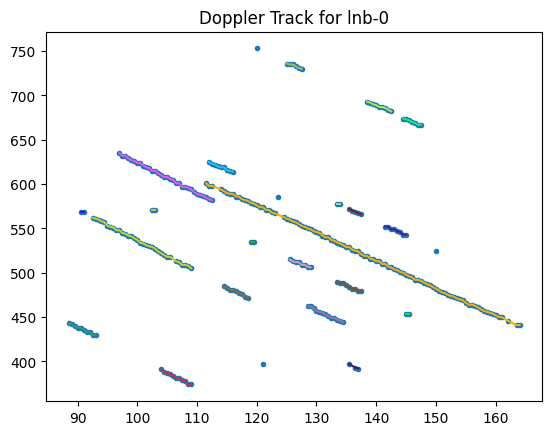

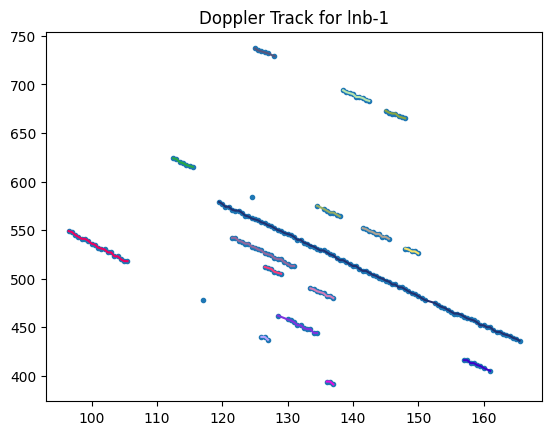

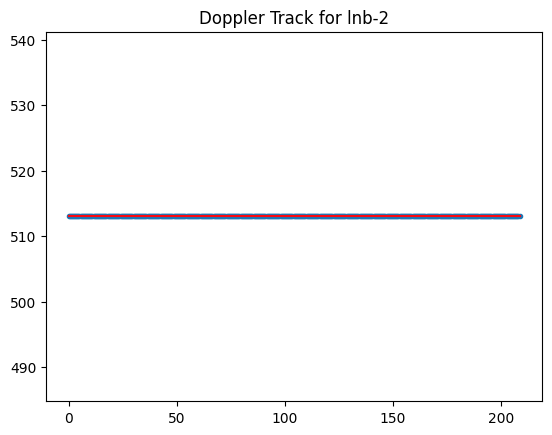

NameError: name 'fc' is not defined

In [2]:
from sat_id import connect_doppler, doppler_sim
track_dict = connect_doppler(date)
output_tracks_file = date+"/output_tracks.mat"
sio.savemat(output_tracks_file, {'tracks_dict': track_dict})
sim_start_time = start_time+loc_sig_idx/sample_rate
sim_end_time = start_time+loc_sig_idx/sample_rate+160
sat_dopp_dict, t_list = doppler_sim(date, '12_27/Starlink.tle', fc, sim_start_time, sim_end_time, 0.5)

In [12]:
# convert sat_dopp_dict to a .mat structure
# save sat_dopp_dict, t_list to .mat file
output_doppler_file = date+"/output_doppler.mat"
output = {}
sio.savemat(output_doppler_file, {'sat_dopp_dict': sat_dopp_dict, 't_list': t_list})

[array([[(array([[  0.5, 487. ]]), array([[  1., 457.]]), array([[  1.5, 447. ]]), array([[ 17. , 440. ],
                [ 18.5, 437. ],
                [ 19. , 435. ]]), array([[ 22.5, 425. ],
                [ 23. , 425. ],
                [ 24.5, 420. ],
                [ 25. , 419. ],
                [ 27. , 414. ],
                [ 29. , 410. ],
                [ 29.5, 408. ],
                [ 30. , 407. ]]), array([[ 32., 680.],
                [ 34., 677.],
                [ 36., 674.]]), array([[ 41.5, 418. ]]), array([[ 41.5, 485. ],
                [ 42. , 485. ]]), array([[ 46., 400.]]), array([[ 48.5, 473. ]]), array([[ 52.5, 426. ],
                [ 53. , 424. ],
                [ 53.5, 424. ],
                [ 54. , 420. ],
                [ 54.5, 418. ],
                [ 55. , 418. ],
                [ 55.5, 416. ],
                [ 56. , 414. ],
                [ 56.5, 414. ],
                [ 57.5, 411. ]]), array([[ 54.5, 375. ],
                [ 55. , 375. ]

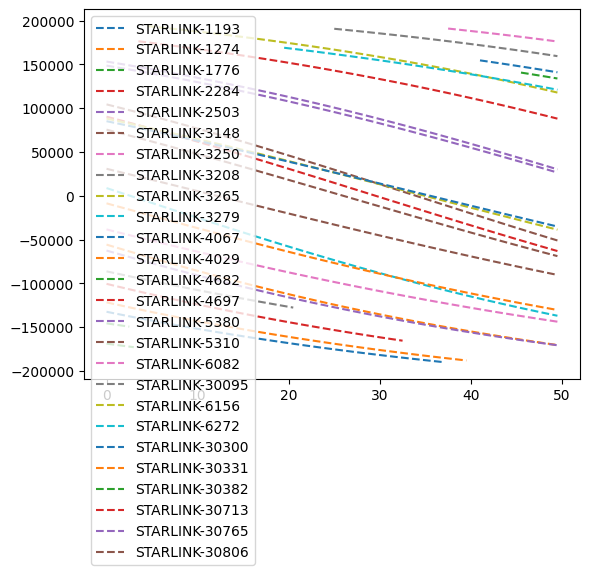

In [9]:
from matplotlib import pyplot as plt
import numpy as np
# iterate through sat_dopp_dict
for sat in sat_dopp_dict:
    dopp = sat_dopp_dict[sat]
    # judge if dopp is all nan
    if not np.isnan(dopp).all():
        plt.plot(t_list, sat_dopp_dict[sat], label=sat, linestyle='--')
plt.legend()
track_dict = sio.loadmat(output_tracks_file)['tracks_dict'][0]
print(track_dict)
